# Candidate Models

### Random Forest
An ensemble of decision trees trained with bagging. It was chosen because it:
- captures nonlinear effects and feature interactions without manual feature engineering,
- needs little tuning and is hard to overfit badly,
- provides feature importances that help interpret which factors drive turnout,
- is a different type of ensemble (bagging) from XGBoost (boosting), which gives an independent comparison.

### XGBoost
A gradient boosting model that builds trees sequentially, with each tree correcting the errors of the previous ones. It is typically the strongest performer on tabular data of this kind, and it handles interactions such as the effect of `elo_diff` depending on `log_capacity` or `day_type`. LightGBM was not trained as well, because it is another gradient boosting implementation and would be expected to perform within noise of XGBoost on a dataset of this size, adding little new information.

### Support Vector Machine (RBF kernel)
Added for diversity. Logistic regression is linear and Random Forest and XGBoost are tree-based, while an RBF SVM learns smooth, curved decision boundaries in the scaled feature space. Models that make different kinds of errors combine better in an ensemble, which is the main reason for including it. It is trained inside a pipeline with a scaler and wrapped in `CalibratedClassifierCV` (sigmoid calibration), so that it can output the class probabilities needed for ROC AUC and for the ensembles. `SVC(probability=True)` is deprecated in scikit-learn 1.9, which is why the wrapper is used.

## Ensemble models

### Soft voting
Averages the predicted class probabilities of logistic regression, Random Forest, XGBoost, and SVM. It is simple, has no extra parameters to fit, and is unlikely to overfit, which makes it a reasonable first ensemble.

### Stacking
Trains a logistic regression on top of the out-of-fold predictions of the base models, so it learns how much to trust each one. It can outperform voting but is more prone to overfitting and slower to train. The out-of-fold predictions come from season-grouped cross-validation: each fold holds out whole seasons, so the base models always predict a season they did not train on.


## 1. Setup

In [1]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

print(
    f"scikit-learn {sklearn.__version__} | "
    f"xgboost {xgboost.__version__} | pandas {pd.__version__}"
)

scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 3.0.6


In [ ]:
RANDOM_STATE = 42
N_JOBS = -1        # use all CPU cores where a model supports it

DATA_DIR = Path("../data")
TRAIN_TEST_DIR = DATA_DIR / "train_test_df"
FEATURES_DIR = DATA_DIR / "processed" / "features"

# Outputs
RESULT_DIR = Path("../results")
CANDIDATE_DIR = RESULT_DIR / "candidate_models"

## 2. Helper functions

The helpers keep the training, scoring, display and saving steps identical for every model, so a new model only needs to be added to the `models` dictionary.

In [3]:
def fit_and_predict(models, X_train, y_train, X_test):
    """Fit each model once and return test predictions, probabilities and fit times."""
    preds, probas, fit_seconds = {}, {}, {}
    for name, model in models.items():
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds[name] = time.perf_counter() - start
        preds[name] = model.predict(X_test)
        probas[name] = model.predict_proba(X_test)
    return preds, probas, fit_seconds


def score_model(y_true, y_pred, y_proba):
    """Return the headline metrics for one model."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "roc_auc_ovr": roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro"),
    }


def style_summary(results_df, title):
    """Styled comparison table: darker blue is better, best value per column in green."""
    return (
        results_df.style
        .format("{:.3f}")
        .background_gradient(cmap="Blues", axis=0)
        .highlight_max(axis=0, props="font-weight: bold; color: #0a7d32;")
        .set_caption(title)
        .set_table_styles([{
            "selector": "caption",
            "props": [("font-size", "16px"), ("font-weight", "bold"), ("text-align", "left")],
        }])
    )


def make_report_df(y_true, y_pred, labels, class_names):
    """Per-class precision, recall and F1 as a DataFrame."""
    report = classification_report(
        y_true, y_pred, labels=labels, target_names=class_names,
        output_dict=True, zero_division=0,
    )
    report_df = pd.DataFrame(report).T
    # sklearn repeats the accuracy value in every column of its row. Keep it
    # under f1-score only, and use the row count as its support.
    if "accuracy" in report_df.index:
        report_df.loc["accuracy", ["precision", "recall"]] = float("nan")
        report_df.loc["accuracy", "support"] = len(y_true)
    report_df["support"] = report_df["support"].astype(int)
    return report_df


def show_class_reports(names, preds, y_true, labels, class_names):
    """Display a styled per-class report for each model."""
    for name in names:
        print(f"\n{name}")
        display(
            make_report_df(y_true, preds[name], labels, class_names).style
            .format(
                {"precision": "{:.3f}", "recall": "{:.3f}",
                 "f1-score": "{:.3f}", "support": "{:d}"},
                na_rep="",
            )
            .background_gradient(cmap="Greens", subset=["precision", "recall", "f1-score"])
        )


def plot_confusion_matrices(names, preds, y_true, labels, class_names,
                            ncols=4, save_path=None, show=True):
    """Grid of confusion matrices normalized by true class (rows sum to 1)."""
    names = list(names)
    ncols = min(ncols, len(names))
    nrows = -(-len(names) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.2 * nrows), squeeze=False)
    axes = axes.ravel()

    for ax, name in zip(axes, names):
        ConfusionMatrixDisplay.from_predictions(
            y_true, preds[name],
            labels=labels, display_labels=class_names,
            normalize="true", values_format=".2f",
            cmap="Blues", colorbar=False, ax=ax,
        )
        ax.set_title(name, fontsize=13, fontweight="bold")
        ax.grid(False)

    for ax in axes[len(names):]:  # hide unused panels
        ax.axis("off")

    fig.suptitle("Confusion matrices (normalized by true class)", fontsize=16, fontweight="bold")
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)

## 3. Load the train/test split and validate it

The split was saved by the 02_baseline_models notebook as unscaled features. The checks below confirm that the files load as expected: same columns in the same order as the saved feature config, features and targets aligned, no missing values, and integer class codes `0, 1, 2` (XGBoost requires classes numbered from 0).

The season is not part of the saved features, so it is read from the full training table (`train_features.csv`). The rows of that table are compared with `X_train` value by value, so each game's season is guaranteed to belong to the right row.

In [4]:
X_train = pd.read_csv(TRAIN_TEST_DIR / "X_train.csv")
X_test = pd.read_csv(TRAIN_TEST_DIR / "X_test.csv")

# Select the target column so y is a Series, not a one-column DataFrame
y_train = pd.read_csv(TRAIN_TEST_DIR / "y_train.csv")["target"]
y_test = pd.read_csv(TRAIN_TEST_DIR / "y_test.csv")["target"]

with open(FEATURES_DIR / "feature_config.json") as f:
    config = json.load(f)

CLASS_LABELS = {int(code): name for code, name in config["class_labels"].items()}
labels = sorted(CLASS_LABELS)
class_names = [CLASS_LABELS[i] for i in labels]

# Structure checks
assert X_train.columns.tolist() == config["output_columns"]
assert X_test.columns.tolist() == X_train.columns.tolist()
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert not X_train.isna().any().any() and not X_test.isna().any().any()
assert y_train.notna().all() and y_test.notna().all()

# Class codes must be 0..K-1 and identical in both sets
assert labels == list(range(len(labels)))
assert sorted(y_train.unique()) == labels == sorted(y_test.unique())

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)

class_counts = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "test_count": y_test.value_counts(),
}).sort_index()
class_counts["train_share"] = class_counts["train_count"] / len(y_train)
class_counts["test_share"] = class_counts["test_count"] / len(y_test)
class_counts.index = class_counts.index.map(CLASS_LABELS)
class_counts.index.name = "turnout_class"

display(class_counts.style.format({"train_share": "{:.1%}", "test_share": "{:.1%}"}))

X_train: (1559, 32) | y_train: (1559,)
X_test:  (806, 32) | y_test:  (806,)


,train_count,test_count,train_share,test_share
turnout_class,,,,
low,520,238,33.4%,29.5%
medium,519,311,33.3%,38.6%
high,520,257,33.4%,31.9%


In [5]:
# Season of every training game, used to build the stacking CV folds
train_full = pd.read_csv(FEATURES_DIR / "train_features.csv")

# Confirm the rows line up with X_train by comparing the feature values
assert len(train_full) == len(X_train)
pd.testing.assert_frame_equal(
    train_full[X_train.columns].reset_index(drop=True),
    X_train,
    check_dtype=False,
    rtol=1e-6,
)

season_train = train_full["season"]
print("training seasons:", sorted(season_train.unique().tolist()))
display(season_train.value_counts().sort_index().rename("games").to_frame())

training seasons: [2023, 2024]


,games
season,
2023,787
2024,772


**Observation.** The split has 1,559 training and 806 test games with 32 features, and all checks pass, including the row alignment between `X_train` and the season column. The test set is reasonably balanced (`low` 238, `medium` 311, `high` 257, so the largest class is 38.6%).

## 4. Define the models

Logistic regression is rebuilt here with the same settings as the baseline notebook (scaler plus `LogisticRegression`, `max_iter=2000`) instead of being loaded from disk. This keeps the notebook self-contained and means every model is trained fresh in one pass.

Both ensembles receive the same four base models. `VotingClassifier` and `StackingClassifier` clone the estimators they are given, so fitting an ensemble never changes the standalone models. The dummy baseline is not part of either ensemble.

Stacking receives precomputed season-grouped folds (see the explanation below). The printout below shows which seasons each fold holds out.

**Why stacking needs folds.** The meta-model has to learn from predictions that the base models made on games they had not trained on. Predictions on their own training games are too good, so the meta-model would learn to over-trust every base model. To avoid this, the training games are split into folds. The base models train on all folds except one, predict the held-out fold, and this repeats until every training game has an out-of-fold prediction. The meta-model learns from those predictions. Afterwards the base models are refit on all the training data to predict the test set.

**Why the folds are split by season.** Games from the same season share teams, ratings and context. If a 2022 game were predicted by models that studied other 2022 games, the prediction would look better than it would on a season the models have never seen, and the meta-model would trust the base models too much. With season folds, whole seasons are held out together. For example, with three training seasons:

| Fold | Base models study | Base models predict |
|---|---|---|
| 1 | 2023, 2024 | 2022 |
| 2 | 2022, 2024 | 2023 |
| 3 | 2022, 2023 | 2024 |

This is closer to the real task of predicting a season that has not happened yet. The notebook uses `GroupKFold` with up to 5 folds, and never more folds than there are seasons in the training data. Only stacking uses these folds. Soft voting and the individual models are trained on the full training set in the usual way.

In [6]:
# Floor
dummy_model = DummyClassifier(strategy="most_frequent")

# Scale-sensitive models:
logreg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

# SVC has no built-in probabilities in the new scikit-learn API, so the
# calibration wrapper adds them (needed for ROC AUC and for the ensembles)
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", CalibratedClassifierCV(
        SVC(kernel="rbf"),
        method="sigmoid",
        ensemble=False,  # fit the SVC once, use CV only to learn the calibration
        cv=5,
    )),
])

# Tree models: scale-invariant, so no scaler
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(labels),
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
)

In [7]:
base_estimators = [
    ("logreg", logreg_model),
    ("svm", svm_model),
    ("rf", rf_model),
    ("xgb", xgb_model),
]

# Average of the base models' predicted probabilities
voting_model = VotingClassifier(estimators=base_estimators, voting="soft")

# Season-based folds: each fold holds out whole seasons, so the base models
# always predict a season they did not train on
n_folds = min(5, season_train.nunique())
cv_splits = list(
    GroupKFold(n_splits=n_folds).split(X_train, y_train, groups=season_train)
)
for i, (_, held_out) in enumerate(cv_splits, start=1):
    print(f"stacking fold {i}: holds out seasons {sorted(season_train.iloc[held_out].unique().tolist())}")

# A logistic regression learns how much to trust each base model, using the
# out-of-fold probabilities from the folds above
stacking_model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    cv=cv_splits,
    n_jobs=N_JOBS,
)

models = {
    "dummy": dummy_model,
    "logreg": logreg_model,
    "svm": svm_model,
    "random_forest": rf_model,
    "xgboost": xgb_model,
    "voting_soft": voting_model,
    "stacking_cv": stacking_model,
}
print("Models to train:", list(models))

stacking fold 1: holds out seasons [2023]
stacking fold 2: holds out seasons [2024]
Models to train: ['dummy', 'logreg', 'svm', 'random_forest', 'xgboost', 'voting_soft', 'stacking_cv']


## 5. Train and evaluate

Each model, ensembles included, is fitted exactly once on the training set and scored on the test set. Predictions and probabilities are kept so that every table, plot and saved file below reuses them without refitting.

In [8]:
preds, probas, fit_seconds = fit_and_predict(models, X_train, y_train, X_test)

fit_times = pd.Series(fit_seconds, name="fit_seconds").round(2).to_frame()
display(fit_times)

,fit_seconds
dummy,0.00
logreg,0.04
svm,0.26
random_forest,0.36
xgboost,0.28
voting_soft,0.85
stacking_cv,9.09


In [9]:
results_df = (
    pd.DataFrame({name: score_model(y_test, preds[name], probas[name]) for name in models})
    .T.rename_axis("model")
    .sort_values("f1_macro", ascending=False)
)

display(style_summary(results_df, "Final model comparison (test set)"))

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
model,,,,,,
voting_soft,0.775,0.788,0.775,0.788,0.778,0.921
random_forest,0.767,0.778,0.770,0.778,0.770,0.915
logreg,0.757,0.768,0.762,0.768,0.761,0.909
stacking_cv,0.758,0.772,0.759,0.772,0.760,0.919
xgboost,0.757,0.770,0.757,0.770,0.759,0.912
svm,0.742,0.754,0.743,0.754,0.746,0.864
dummy,0.295,0.333,0.098,0.333,0.152,0.500


### Observations: model comparison

- **Every trained model is far above the floor.** The dummy baseline scores 0.295 accuracy, 0.152 macro F1 and 0.500 ROC AUC (chance level). The trained models reach 0.742 to 0.775 accuracy.
- **`voting_soft` ranks first on every metric** (accuracy 0.775, macro F1 0.778, ROC AUC 0.921). It beats each of its own members, with Random Forest the closest (macro F1 0.770, AUC 0.915). This fits the idea behind soft voting: combining a linear model with tree models averages out their different errors.
- **The gaps between the top models are small.** Macro F1 for the six trained models runs from 0.746 to 0.778. With 806 test games, the standard error of an accuracy near 0.77 is about 1.5 points, and one point is roughly 8 games. The ranking among the leading models is suggestive, not conclusive.
- **Stacking is competitive but does not beat voting.** It scores accuracy 0.758, macro F1 0.760 and ROC AUC 0.919. Its ROC AUC is the second best (behind voting), and on class decisions it sits level with logistic regression and XGBoost, yet it stays below voting on every metric and below Random Forest on macro F1 (0.760 vs 0.770). Learned weights are not beating equal weights here, plausibly because the meta-model learns from only about 1,500 games (not tested). Stacking also costs more, since it refits every base model once per fold.
- **Logistic regression matches XGBoost** (accuracy 0.757 for both, macro F1 0.761 vs 0.759). A simple linear model keeping pace with boosting suggests most of the predictive signal already sits in the engineered features (Elo, prior turnout, capacity), and extra model complexity buys little. This is an inference from the scores, not something tested directly.
- **The SVM is the weakest trained model**, mainly on ROC AUC (0.864 vs 0.909 to 0.921 for the others), while its accuracy gap is smaller (0.742). So its predicted probabilities rank games worse than the other models. Its `C` and `gamma` were left at defaults and the probabilities come from sigmoid calibration, which are the likely causes, but neither was tested here.
- **Balanced accuracy and macro recall are identical in every row**, as expected, because they are the same quantity.

## 6. Per-class performance

In [10]:
show_class_reports(results_df.index, preds, y_test, labels, class_names)


voting_soft


,precision,recall,f1-score,support
low,0.782,0.891,0.833,238
medium,0.760,0.643,0.697,311
high,0.783,0.829,0.805,257
accuracy,,,0.775,806
macro avg,0.775,0.788,0.778,806
weighted avg,0.774,0.775,0.772,806



random_forest


,precision,recall,f1-score,support
low,0.729,0.891,0.802,238
medium,0.751,0.650,0.697,311
high,0.829,0.794,0.811,257
accuracy,,,0.767,806
macro avg,0.770,0.778,0.770,806
weighted avg,0.769,0.767,0.764,806



logreg


...

,precision,recall,f1-score,support
low,0.743,0.861,0.798,238
medium,0.739,0.611,0.669,311
high,0.788,0.837,0.811,257
accuracy,,,0.757,806
macro avg,0.757,0.770,0.759,806
weighted avg,0.756,0.757,0.752,806



svm


,precision,recall,f1-score,support
low,0.785,0.845,0.814,238
medium,0.712,0.605,0.654,311
high,0.731,0.813,0.770,257
accuracy,,,0.742,806
macro avg,0.743,0.754,0.746,806
weighted avg,0.740,0.742,0.738,806



dummy


,precision,recall,f1-score,support
low,0.295,1.000,0.456,238
medium,0.000,0.000,0.000,311
high,0.000,0.000,0.000,257
accuracy,,,0.295,806
macro avg,0.098,0.333,0.152,806
weighted avg,0.087,0.295,0.135,806


### Observations: per-class results

- **`medium` is the hardest class for every model.** Its F1 is 0.654 to 0.697, against 0.798 to 0.833 for `low` and roughly 0.77 to 0.81 for `high`. It sits between two class boundaries, so games close to either cutoff can fall on either side (assuming the classes are turnout-rate bins, which the leakage note in the feature step suggests).
- **Models are cautious about predicting `medium`.** For all six trained models, `medium` precision (0.712 to 0.760) is higher than its recall (0.605 to 0.650), so they predict it less often than it occurs and push those games to `low` or `high`.
- **`low` is found reliably.** Recall is 0.815 to 0.899, highest for stacking (0.899), followed by voting and Random Forest (both 0.891). Stacking pays for it with one of the lowest `low` precisions (0.728, level with Random Forest at 0.729), which means it labels some `medium` games as `low`.
- **`high` recall is 0.79 to 0.87**, highest for logistic regression (0.872), which pays for it with the lowest `high` precision of all models (0.723). Stacking is the most balanced here (precision 0.801, recall 0.813, F1 0.807).
- **`voting_soft` is best or near best on every class.** Its F1 is the highest on `low` (0.833), ties Random Forest on `medium` (0.697), and is within about 0.01 of the best on `high` (0.805). That consistency is where its macro F1 lead comes from.

## 7. Confusion matrices

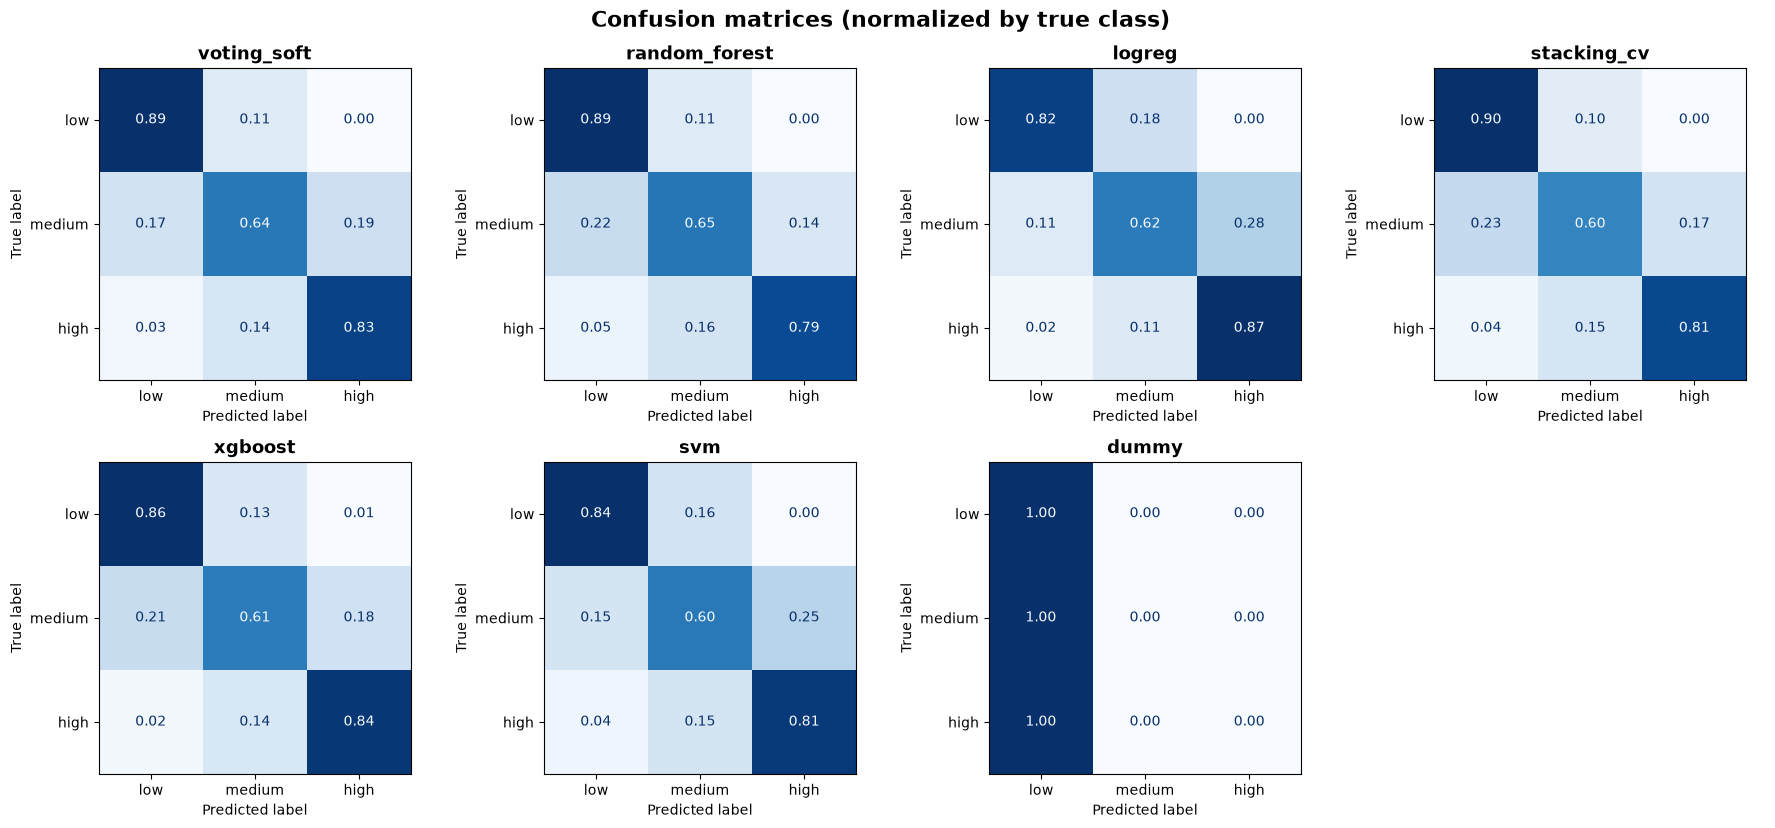

In [11]:
plot_confusion_matrices(results_df.index, preds, y_test, labels, class_names)

### Observations: where the models make mistakes

- **Mistakes are almost always to the neighbouring class.** `low` games predicted as `high` are 0.00 to 0.01 of the row for every model, and `high` games predicted as `low` are 0.02 to 0.05. The costly error of confusing the two extremes is rare.
- **The models miss `medium` in opposite directions.** Logistic regression and the SVM send many `medium` games to `high` (0.28 and 0.25), while Random Forest, XGBoost and stacking lean towards `low` (0.22, 0.21 and 0.23). `voting_soft` is the most balanced (0.17 to `low`, 0.19 to `high`). Because the members err in opposite directions, averaging them helps, which is the main reason the voting ensemble works here.
- **The target is ordered** (`low` < `medium` < `high`) and the error pattern follows that order, so a model that uses the ordering might help the `medium` class.

## 8. Conclusions

**Candidate for the final model: `voting_soft`.** It is first on every metric, has the best ROC AUC (0.921), and has the most balanced errors across classes. Its lead over Random Forest (macro F1 +0.008) and logistic regression (+0.017) is small and within single-split noise, so the choice rests on consistency across all metrics more than on a clear win. If simplicity matters more than the last point of F1, Random Forest (one model, feature importances) or logistic regression (one model, interpretable coefficients) are reasonable alternatives, since voting requires fitting and serving four models, including a calibrated SVM.

## 9. Save results

In [12]:
CANDIDATE_DIR.mkdir(parents=True, exist_ok=True)
run_time = datetime.now(timezone.utc).isoformat(timespec="seconds")

# Files shared by all models
results_df.round(4).to_csv(CANDIDATE_DIR / "model_comparison.csv")

prediction_columns = {"y_true": y_test.to_numpy()}
for name in models:
    prediction_columns[f"{name}_pred"] = preds[name]
    for i, class_name in enumerate(class_names):
        prediction_columns[f"{name}_proba_{class_name}"] = probas[name][:, i]
pd.DataFrame(prediction_columns).round(4).to_csv(
    CANDIDATE_DIR / "test_predictions.csv", index=False
)

with open(CANDIDATE_DIR / "feature_columns.json", "w") as f:
    json.dump(X_train.columns.tolist(), f, indent=2)

plot_confusion_matrices(
    results_df.index, preds, y_test, labels, class_names,
    save_path=CANDIDATE_DIR / "confusion_matrices.png", show=False,
)

# One folder per model
for name in results_df.index:
    model_dir = CANDIDATE_DIR / name
    model_dir.mkdir(exist_ok=True)

    make_report_df(y_test, preds[name], labels, class_names).round(4).to_csv(
        model_dir / "classification_report.csv"
    )

    counts = pd.DataFrame(
        confusion_matrix(y_test, preds[name], labels=labels),
        index=[f"true_{c}" for c in class_names],
        columns=[f"pred_{c}" for c in class_names],
    )
    counts.to_csv(model_dir / "confusion_matrix_counts.csv")
    counts.div(counts.sum(axis=1), axis=0).round(4).to_csv(
        model_dir / "confusion_matrix_normalized.csv"
    )

    joblib.dump(models[name], model_dir / f"{name}.joblib")

    metadata = {
        "model_name": name,
        "estimator_class": type(models[name]).__name__,
        "trained_at_utc": run_time,
        "fit_seconds": round(fit_seconds[name], 2),
        "n_train_rows": len(X_train),
        "n_features": X_train.shape[1],
        "test_metrics": results_df.loc[name].round(4).to_dict(),
        "library_versions": {
            "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__,
            "pandas": pd.__version__,
        },
        # Top-level settings only, as text, so nested estimators serialize safely.
        # Precomputed CV folds are summarised instead of dumping index arrays.
        "params": {
            k: (f"{len(v)} precomputed season-grouped folds" if k == "cv" and isinstance(v, list) else str(v))
            for k, v in models[name].get_params(deep=False).items()
        },
    }
    with open(model_dir / "metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

print("Saved to:", CANDIDATE_DIR.resolve())
for path in sorted(CANDIDATE_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(CANDIDATE_DIR)}  ({path.stat().st_size / 1024:.0f} KB)")

Saved to: C:\Users\emirl\Sports-Analytics-1B-assessing-football-stadium-attendance-and-experience\results\candidate_models
  confusion_matrices.png  (362 KB)
  dummy\classification_report.csv  (0 KB)
  dummy\confusion_matrix_counts.csv  (0 KB)
  dummy\confusion_matrix_normalized.csv  (0 KB)
  dummy\dummy.joblib  (1 KB)
  dummy\metadata.json  (1 KB)
  feature_columns.json  (1 KB)
  logreg\classification_report.csv  (0 KB)
  logreg\confusion_matrix_counts.csv  (0 KB)
  logreg\confusion_matrix_normalized.csv  (0 KB)
  logreg\logreg.joblib  (4 KB)
  logreg\metadata.json  (1 KB)
  model_comparison.csv  (0 KB)
  random_forest\classification_report.csv  (0 KB)
  random_forest\confusion_matrix_counts.csv  (0 KB)
  random_forest\confusion_matrix_normalized.csv  (0 KB)
  random_forest\metadata.json  (1 KB)
  random_forest\random_forest.joblib  (15809 KB)
  stacking_cv\classification_report.csv  (0 KB)
  stacking_cv\confusion_matrix_counts.csv  (0 KB)
  stacking_cv\confusion_matrix_normalized.csv